# Severe but Harmless: paper results walkthrough

This notebook reads the released summary files in `artifacts/results/` and shows the main tables and figures from the paper. Run it from the repository root after installing `requirements/analysis.txt`. It needs no datasets, saved forecasts, GPU, or model weights.

The displayed outputs were generated from saved results. This notebook does not rerun forecasting or training. To rebuild the summary files from datasets and saved forecasts, use `scripts/make_results.py` as described in the README.


In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Paths are relative to the repository root.
RES = Path("artifacts/results")
DATASETS = {"metr_la": "METR-LA", "pems_bay": "PEMS-BAY", "largest_sd": "LargeST-SD"}
SHIFTS = ("S1", "S2", "S3")


# Read one released result file without modifying it.
def load(name):
    return json.loads((RES / name).read_text())

## Table II: severity and degradation

S1 compares weekdays with weekends; S2 compares peak with off-peak hours; S3 compares a held-out sensor cluster with the retained sensors. The table reports Wasserstein-1 distance ($W_1$) and the percentage change in mean absolute error (MAE) for the two frozen forecasters. Positive degradation means higher error on the shifted pool; negative values mean lower error.

$W_1$ uses the observable's units: mph for METR-LA and PEMS-BAY, vehicles per 15 minutes for LargeST-SD. Compare its readings within a dataset, not across datasets. For S1 and S2, each sensor is compared with itself across time; S3 compares held-out sensors with a pooled retained-sensor marginal. The degradation reference is the complementary test-period slice for each shift, not the `std` column of Table III.


In [2]:
sev, deg = load("severity.json"), load("degradation.json")
rows = []
for d, label in DATASETS.items():
    for s in SHIFTS:
        rows.append({"dataset": label, "shift": s, "W1": round(sev[d][s]["w1"], 1),
                     "Chronos-2 (%)": round(100 * deg[d]["chronos2"][s]["degradation"]["avg"], 1),
                     "TimesFM (%)": round(100 * deg[d]["timesfm"][s]["degradation"]["avg"], 1)})
pd.DataFrame(rows)

,dataset,shift,W1,Chronos-2 (%),TimesFM (%)
0,METR-LA,S1,4.3,-1.5,-4.5
1,METR-LA,S2,6.8,-28.3,-35.5
2,METR-LA,S3,5.5,18.7,20.6
3,PEMS-BAY,S1,4.2,-51.4,-48.1
4,PEMS-BAY,S2,7.4,-52.9,-54.7
5,PEMS-BAY,S3,3.5,-19.9,-20.1
6,LargeST-SD,S1,55.1,28.6,8.4
7,LargeST-SD,S2,142.2,-33.7,-35.2
8,LargeST-SD,S3,92.6,-26.1,-25.7


## Does severity predict degradation? (Section IV-C)

`rho_18` describes all 18 model–setting evaluations, which are dependent because the two forecasters share each setting. `rho_9` averages the two forecasters within each of the nine settings; `p_9` is the paper's setting-level permutation result. The `w1_vs_skill_change` row uses loss of skill relative to the historical average rather than the MAE change shown above. These correlations describe this audit; they do not establish how severity will behave in every deployment.


In [3]:
corr = load("correlations.json")
pd.DataFrame(corr).T.round(2)

,rho_18,rho_9,p_9
w1,-0.51,-0.47,0.20
ks,-0.24,-0.25,0.51
dmean,-0.44,-0.41,0.28
w1_vs_skill_change,0.10,0.02,0.98


## Table III: MAE on the standard test split and each shift pool

Lower MAE is better. `std` is the entire standard test split, while `s1`, `s2`, and `s3` are the shifted pools. These are absolute errors, in mph for the two speed datasets and vehicles per 15 minutes for LargeST-SD. The percentage degradation in Table II uses a separate, shift-specific in-distribution reference pool; it should not be calculated from `std` here.


In [4]:
grid = load("mae_grid.json")
table = {m: {(DATASETS[d], k): round(grid[d][m][k], 2) for d in DATASETS for k in ("std", "s1", "s2", "s3")}
         for m in grid["metr_la"]}
pd.DataFrame(table).T

METR-LA                   PEMS-BAY                   LargeST-SD  \
               std    s1    s2    s3      std    s1    s2    s3        std   
ha            4.19  3.52  3.44  4.99     2.63  1.71  1.94  2.26      27.93   
arima         5.23  5.45  4.77  5.87     2.23  1.28  1.76  1.84      55.43   
dcrnn         3.16  2.73  2.71  3.73     1.61  1.02  1.23  1.34      21.20   
gwnet         3.04  2.52  2.64  3.59     1.58  1.00  1.22  1.31      18.50   
staeformer    2.94  2.47  2.58  3.45     1.54  0.98  1.18  1.24      18.44   
chronos2      4.65  4.61  4.10  5.34     1.84  1.05  1.37  1.51      21.70   
timesfm       3.91  3.78  3.38  4.56     1.69  1.02  1.24  1.38      22.20   

                                 
               s1     s2     s3  
ha          21.57  20.16  22.32  
arima       42.16  45.47  42.62  
dcrnn       17.73  16.31  16.10  
gwnet       16.21  14.19  14.64  
staeformer  16.17  13.65  14.34  
chronos2    26.14  17.30  16.67  
timesfm     23.82  17.30  17.13

## Table IV: Kendall tau between in-distribution and shifted rankings

A value of 1 means the model order is unchanged. The registered ranking set has seven models on METR-LA and PEMS-BAY, and six on LargeST-SD. STAEformer appears in Table III for LargeST-SD but was not in that dataset's registered ranking set. The next cell lists the six LargeST-SD models from lowest to highest MAE on weekdays and weekends.


In [5]:
rank = load("rankings.json")
pd.DataFrame({s: {DATASETS[d]: round(rank[d][s]["tau"], 3) for d in DATASETS} for s in SHIFTS})

,S1,S2,S3
METR-LA,0.905,0.905,1.0
PEMS-BAY,1.000,1.000,1.0
LargeST-SD,0.333,0.867,1.0


In [6]:
# LargeST-SD S1 rankings behind Fig. 3; rank 1 has the lowest MAE.
r = rank["largest_sd"]["S1"]
pd.DataFrame({"weekdays": r["ranked_in_dist"], "weekends": r["ranked_shifted"]}, index=range(1, 7))

,weekdays,weekends
1,gwnet,gwnet
2,chronos2,dcrnn
3,timesfm,ha
4,dcrnn,timesfm
5,ha,chronos2
6,arima,arima


## Saturday and Sunday on LargeST-SD

The weekend average conceals a difference between the two days. These are percentage changes in MAE relative to the weekday reference pool; positive values mean worse forecasts. This split is descriptive and does not change the registered S1 weekend pool.


In [7]:
pd.DataFrame(load("weekend_days.json")).T.mul(100).round(1)

,saturday,sunday
chronos2,66.7,1.7
timesfm,33.9,-9.5


## The timestamp router

The router chooses among the historical average, Chronos-2, and TimesFM using labeled validation windows for each regime. It then applies the chosen model by weekday or weekend timestamp on the test period. Its weekend test MAE equals the historical average's weekend MAE because that is the model it selects there; the router is a selection rule, not a newly trained forecaster. The `validation_mae` values show the choice was made before test evaluation.


In [8]:
load("router.json")

{'chosen': {'weekday': 'chronos2', 'weekend': 'ha'},
 'validation_mae': {'weekday': {'ha': 20.7576258512267,
   'chronos2': 17.95718720295419,
   'timesfm': 19.505108681228865},
  'weekend': {'ha': 18.014892547637185,
   'chronos2': 28.94179967793386,
   'timesfm': 24.550432571744587}},
 'test': {'full_test': 20.45825968177891, 'weekend': 21.573663160771435}}

## Figures

These are the six static figures released with the paper. The PNG files are for convenient notebook viewing; the matching PDFs are also in `artifacts/figures/`.


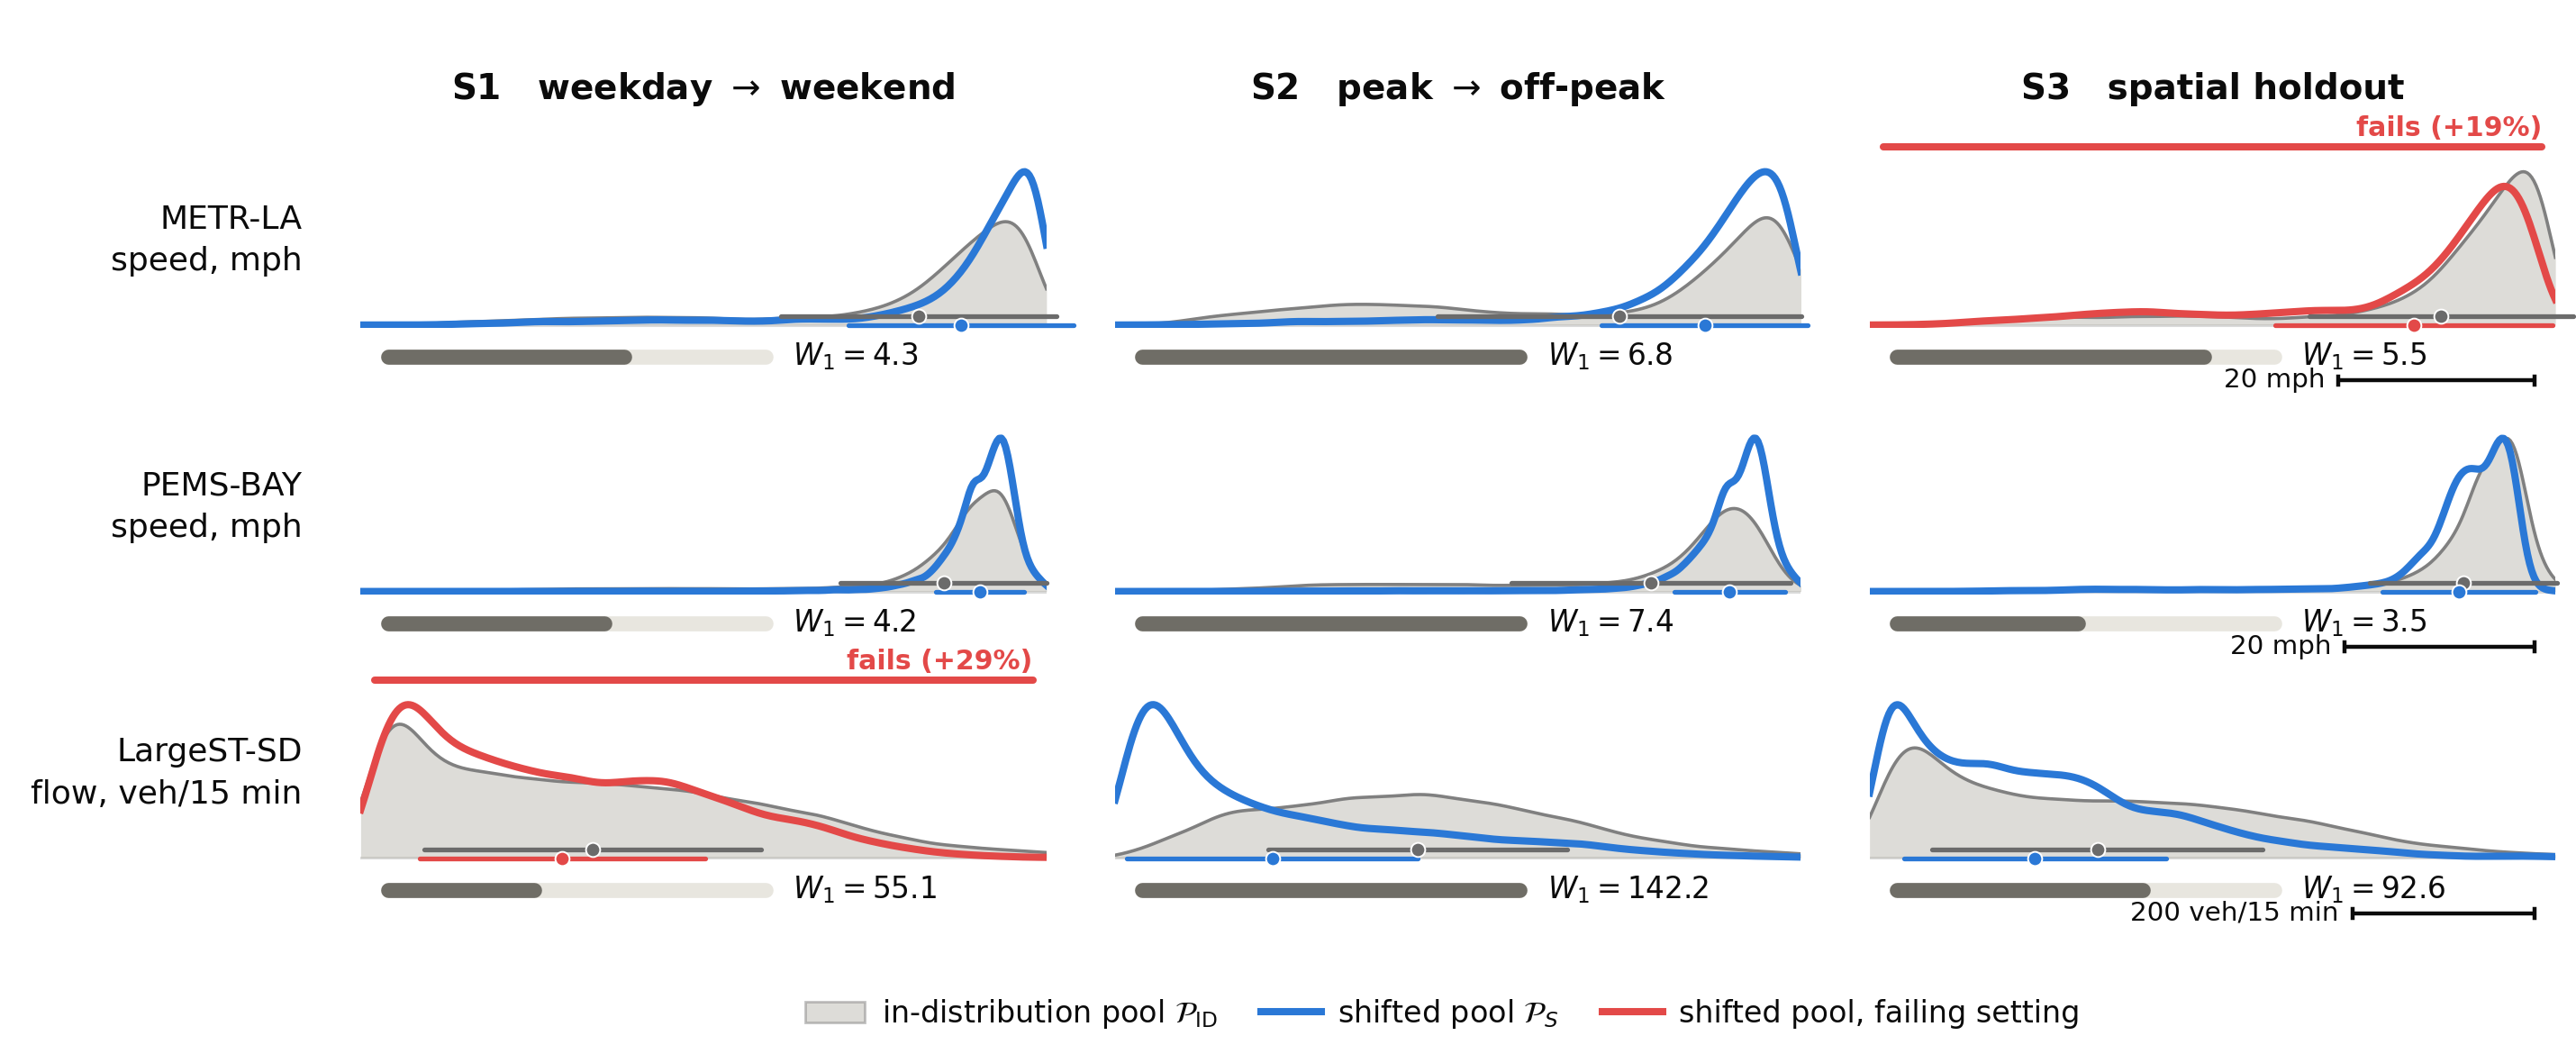

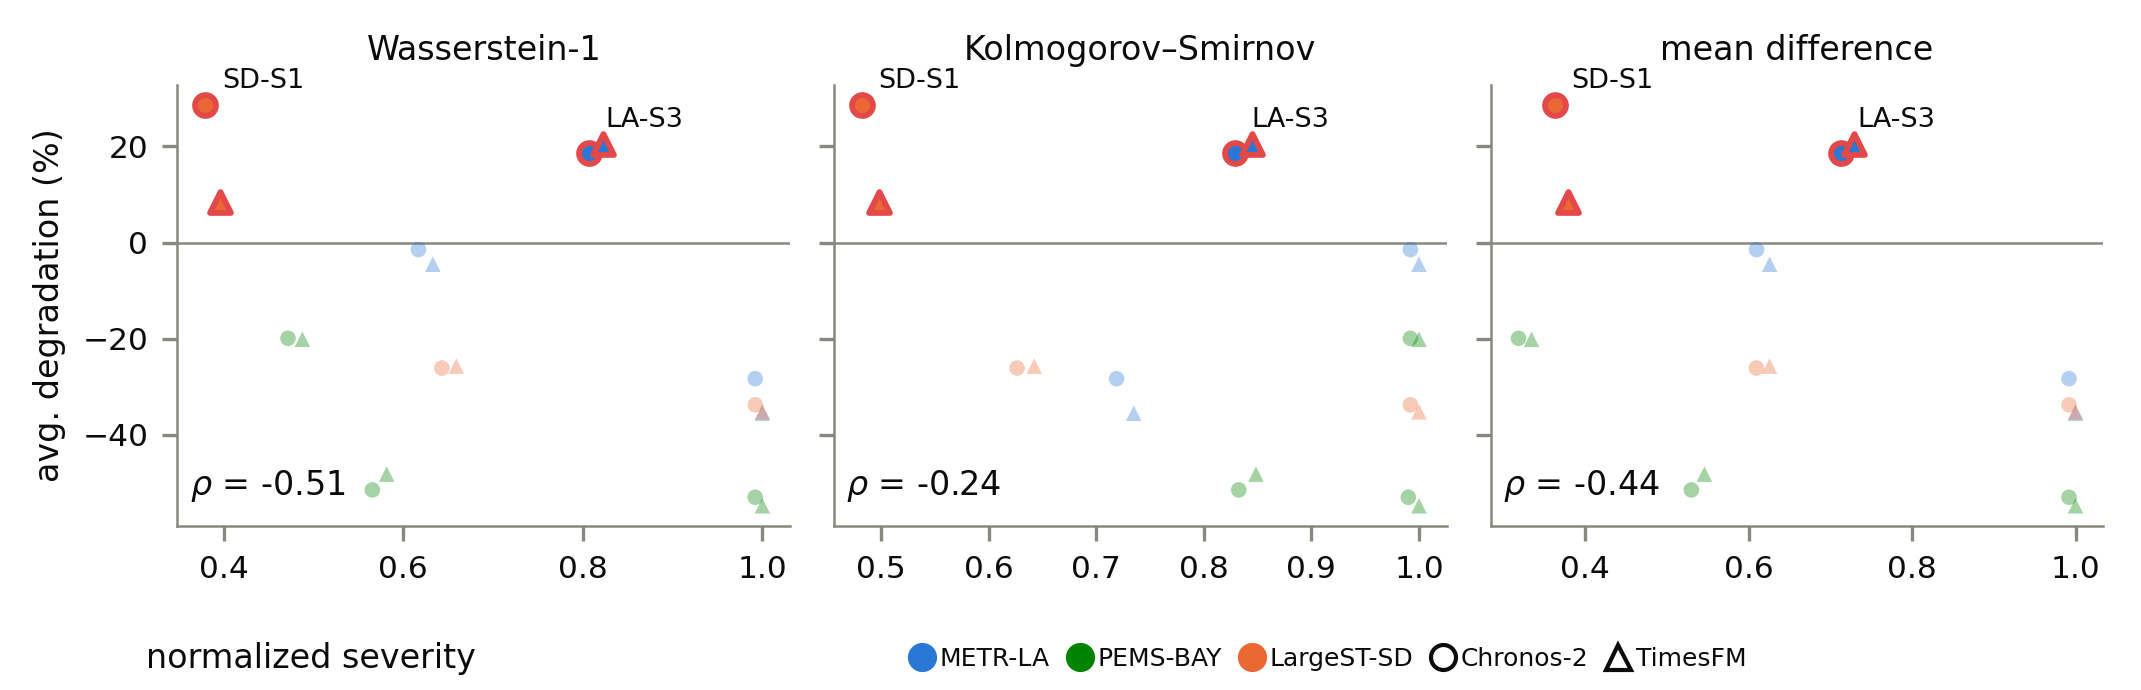

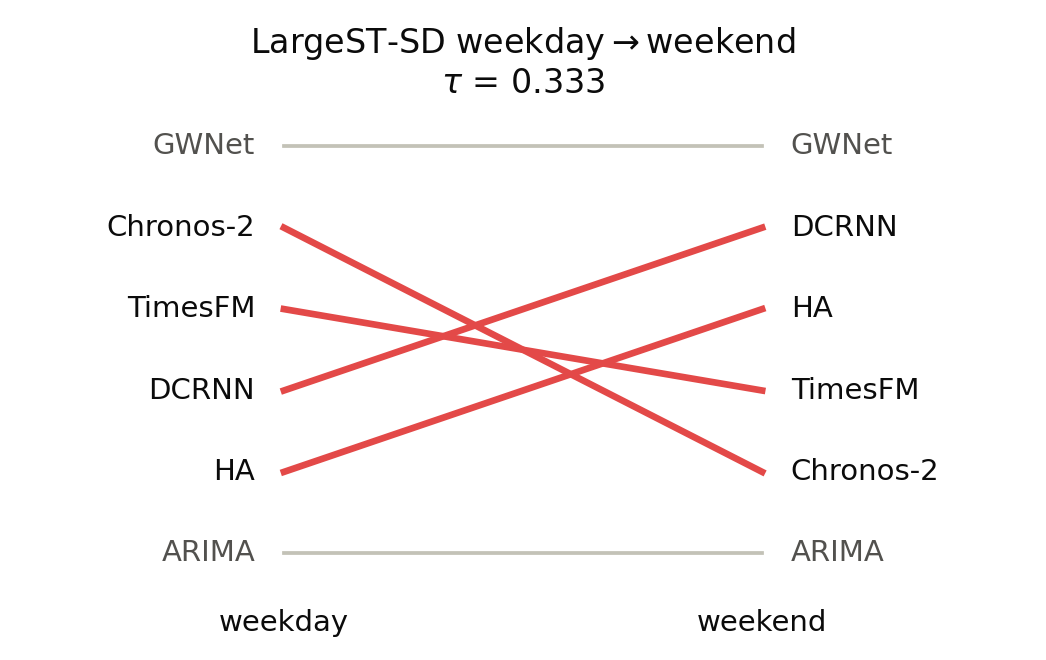

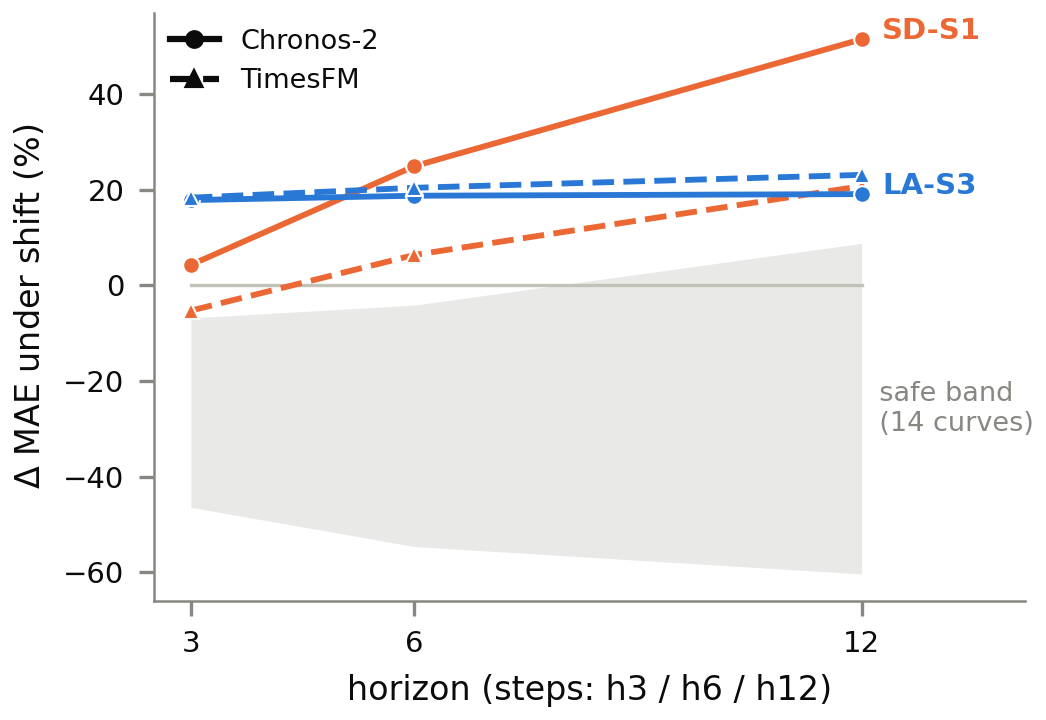

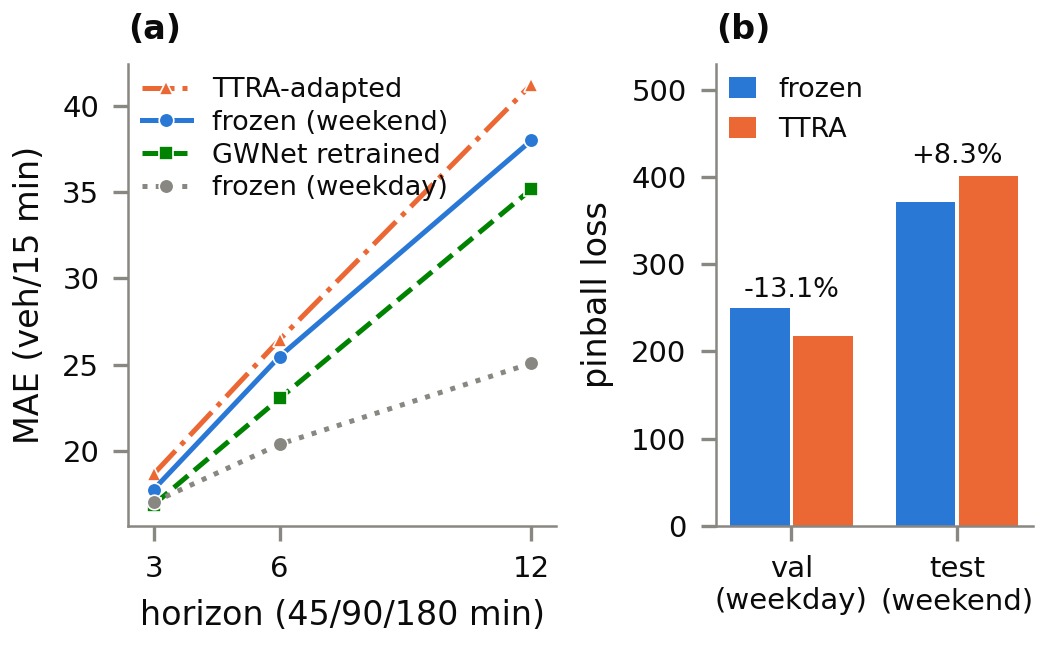

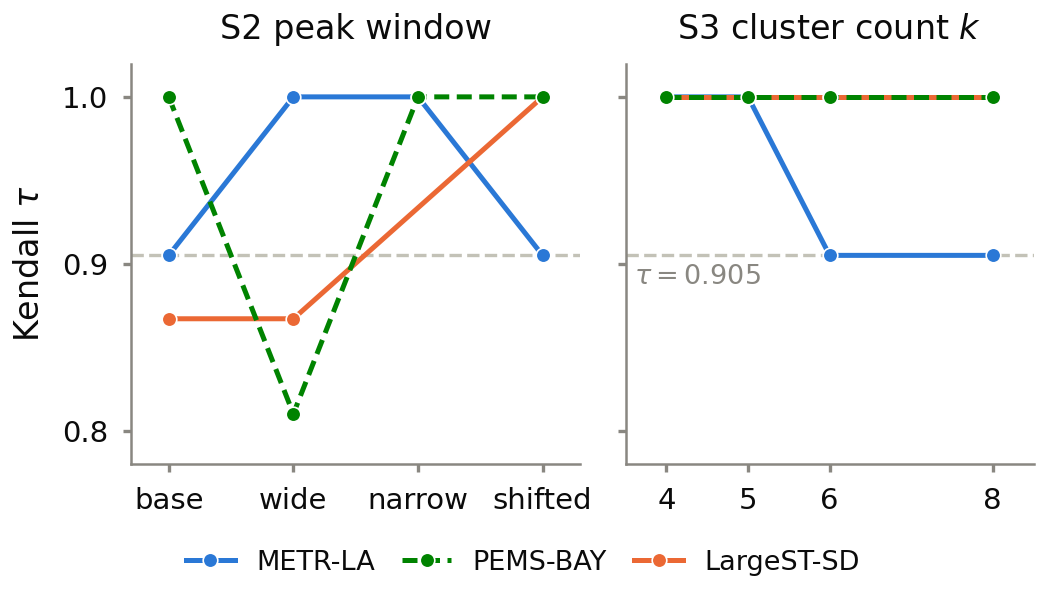

In [9]:
for name in ("F1_shiftgrid", "F5_rulers", "F4_ranking_slopes",
             "G2_degradation_horizon", "F3_sd_s1_case", "G3_split_sensitivity"):
    display(Image(filename=f"artifacts/figures/{name}.png", width=650))

## Check reported values against released result files

The final cell runs `scripts/make_tables.py`, which compares 90 values entered from the paper with the released result files and prints the end of its report. It does not parse the manuscript or independently regenerate forecasts. Run the script directly to see every comparison. A failed check raises an error here.


In [10]:
out = subprocess.run([sys.executable, "scripts/make_tables.py"], capture_output=True, text=True)
print(out.stdout[-1500:])
if out.returncode:
    print(out.stderr)
    raise RuntimeError("Reported-value checks failed; run scripts/make_tables.py for the full report.")

               files yes
  OK   IV-E       GWNet val-to-test gap, plain / normalized (%)  paper 43/26                      files 43/26
  OK   IV-E       router MAE, weekends / full test               paper 21.57/20.46                files 21.57/20.46
  OK   IV-E       router picks (weekday / weekend)               paper chronos2/ha                files chronos2/ha
  OK   IV-E       standard DCRNN / GWNet, full test              paper 21.20/18.50                files 21.20/18.50

Table VI (registered predictions)
  OK   Table VI   P1: SD tau S1 < S2                             paper 0.333/0.867                files 0.333/0.867
  OK   Table VI   P3: STAEformer shifted rank, LA/BAY S1/S2      paper 1,1,1,1                    files 1,1,1,1

Section V (split sensitivity)
  OK   V          peak-window pairs: usable / all                paper 11/12                      files 11/12
  OK   V          usable pairs where off-peak improves           paper 11                         files 11
  OK  